---

# HoloMine Breast Cancer Classification - Task 1

*Mammo-FM EfficientNet-B5 transfer learning with direct three-class supervision, a Benign-vs-Malignant auxiliary head, and explicit storage-mode calibration.*

---

## Individual Research Notebook

- Competition: HoloMine Breast Cancer Classification - Task 1
- Metric: Multiclass Macro F1
- Foundation model: Batman Lab Mammo-FM
- Checkpoint: `Mammo-FM_BatmanlabTrained_CLIP.tar`
- Training: 5-fold high-resolution staged fine-tuning on a single 32 GB CUDA GPU
- Runtime profile: 1520 x 912, batch 4 by default, effective batch 8
- Final prediction: fold ensemble + OOF-calibrated mode prior

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Mammo-FM Setup**](#3)
4. [**Mammogram Preprocessing**](#4)
5. [**Cross-Validation Design**](#5)
6. [**Mammo-FM Multi-Task Model**](#6)
7. [**Training and OOF Inference**](#7)
8. [**OOF Calibration**](#8)
9. [**Test Ensemble**](#9)
10. [**Submission**](#10)
11. [**Experiment Summary**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

*HoloMine Task 1 classifies full-field digital mammograms into `Normal`, `Benign`, and `Malignant`. The training set is extremely small relative to the image resolution, so the central modelling challenge is extracting clinically relevant mammographic features without overfitting the 212 labelled images.*

*Earlier EDA also found a strong dataset-construction shortcut in the original image storage mode. Almost all grayscale `L` images are Normal, while Benign and Malignant images are stored as `RGB`. This notebook keeps that artifact outside the visual encoder and uses it only as an explicit, auditable probability prior.*

## Aim

*The notebook replaces the previous Mammo-CLIP experiment with Mammo-FM, a newer mammography-specific foundation model pretrained on a much larger multi-institutional collection. The model is fine-tuned directly for the three competition classes while an auxiliary Benign-vs-Malignant head strengthens the distinction that remains difficult after the Normal shortcut is accounted for.*

## Metric

***Multiclass Macro F1** gives each of the three classes equal importance and is used for checkpoint selection, calibration, and final local model selection.*

$$Macro\ F1 = \frac{F1_{Normal} + F1_{Benign} + F1_{Malignant}}{3}$$

## Dataset

*Data is sourced from the Kaggle HoloMine Breast Cancer Classification Task 1 competition. The current competition split contains 212 labelled training mammograms and 54 hidden test mammograms.*

```text
Dataset/
|-- sample_submission.csv
|-- test_images/
|-- test.csv
|-- train_images/
`-- train.csv
```

## Approach: Mammo-FM B5 Direct + Pathology Auxiliary

*Mammo-FM is loaded through the authors' own image-encoder implementation and checkpoint configuration rather than approximating the weights with a generic EfficientNet implementation. The original image encoder feeds a direct three-class head and a second head trained only on Benign and Malignant samples.*

```text
Original mammogram
        |
        +--> original PIL mode -----------------------------+
        |                                                   |
        +--> breast crop -> 1520 x 912 -> grayscale RGB    |
                              |                             |
                       Mammo-FM image encoder               |
                              |                             |
                      mammography features                  |
                       /              \                    |
          3-class direct head      B-vs-M auxiliary head   |
                       \              /                    |
                    probability fusion <--------------------+
                              |
                  Normal / Benign / Malignant
```

*Five stratified folds provide out-of-fold predictions and an ensemble whose members each train on 80% of the labelled data. Because patient identifiers are not exposed in the competition CSV, image-level stratification remains a validation limitation.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

This version targets a Linux CUDA workstation with one approximately 32 GB GPU, 16 CPU threads, and fast local NVMe storage. It remains portable through environment-variable overrides, but the defaults are tuned for the supplied machine profile rather than Kaggle.

In [1]:
!nvidia-smi

Sat Sep 19 10:04:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.58.03              Driver Version: 595.58.03      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        On  |   00000000:01:00.0 Off |                  N/A |
|  0%   33C    P8              4W /  500W |     708MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook.

In [2]:
%pip install -q timm==1.0.13 transformers==4.48.0 albumentations==2.0.0 omegaconf==2.3.0 hydra-core==1.3.2 huggingface_hub==0.27.1 hf_xet opencv-python-headless==4.10.0.84 scikit-learn==1.6.1

Note: you may need to restart the kernel to use updated packages.


Mammo-FM is cloned before the imports cell so the authors' `breastclip` modules can be imported from the exact public implementation used by the checkpoint.

In [3]:
!if [ ! -d './Mammo-FM/.git' ]; then git clone -q --depth 1 https://github.com/batmanlab/Mammo-FM.git ./Mammo-FM; else echo 'Reusing existing ./Mammo-FM checkout'; fi
!echo 'Mammo-FM repository ready'

Reusing existing ./Mammo-FM checkout
Mammo-FM repository ready


## Import Libraries

All imports are centralised here, including the official Mammo-FM downstream classifier implementation.

In [4]:
import gc
import math
import os
import random
import subprocess
import sys
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from itertools import product
from pathlib import Path
from types import SimpleNamespace

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from albumentations import Affine, Compose, HorizontalFlip, RandomBrightnessContrast
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader, Dataset

MAMMOFM_CODEBASE = Path.cwd() / 'Mammo-FM' / 'src' / 'codebase'
if not MAMMOFM_CODEBASE.exists():
    raise FileNotFoundError(f'Mammo-FM codebase not found at {MAMMOFM_CODEBASE}')
if str(MAMMOFM_CODEBASE) not in sys.path:
    sys.path.insert(0, str(MAMMOFM_CODEBASE))
from Classifiers.models.breast_clip_classifier import BreastClipClassifier

warnings.filterwarnings('ignore')
cv2.setNumThreads(1)

/venv/main/lib/python3.12/site-packages/albumentations/__init__.py:24: UserWarning: A new version of Albumentations is available: '2.0.8' (you have '2.0.0'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


Successfully imported and registered ModernBERT modules


[nltk_data] Downloading package punkt to /workspace/Mammo-
[nltk_data]     FM/src/codebase/breastclip/../../nltk_data...
[nltk_data]   Package punkt is already up-to-date!


## Seed Everything

A fixed seed controls fold construction, augmentation, and head initialisation.

In [5]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything(42)

## Settings

All paths and hyperparameters are centralised here. The defaults prioritise the full Mammo-FM encoder and high-resolution inputs rather than a small-model benchmark.

In [6]:
class Settings:
    SEED = 42
    ROOT = Path.cwd()
    LOCAL_CANDIDATES = [
        ROOT / 'data',
    ]

    OUTPUT_DIR = Path(os.environ.get('HOLOGY_OUTPUT_DIR', str(ROOT / 'hology_mammofm_workstation_v2')))
    CACHE_DIR = OUTPUT_DIR / 'cache_1520x912'
    CHECKPOINT_DIR = OUTPUT_DIR / 'fold_checkpoints'
    RESULT_DIR = OUTPUT_DIR / 'results'

    N_FOLDS = int(os.environ.get('HOLOGY_N_FOLDS', '5'))
    IMG_H = 1520
    IMG_W = 912
    N_GPU = torch.cuda.device_count()
    GPU_VRAM_GB = (torch.cuda.get_device_properties(0).total_memory / 1024**3) if N_GPU else 0.0
    CPU_COUNT = os.cpu_count() or 4
    NUM_WORKERS = int(os.environ.get('HOLOGY_NUM_WORKERS', str(min(8, max(2, CPU_COUNT // 2)))))
    PREPROCESS_WORKERS = int(os.environ.get('HOLOGY_PREPROCESS_WORKERS', str(min(8, max(2, CPU_COUNT // 2)))))
    DEFAULT_BATCH = 2 if GPU_VRAM_GB >= 24 else 1
    BATCH_SIZE = int(os.environ.get('HOLOGY_BATCH_SIZE', str(DEFAULT_BATCH)))
    TARGET_EFFECTIVE_BATCH = int(os.environ.get('HOLOGY_EFFECTIVE_BATCH', '8'))
    ACCUM_STEPS = max(1, math.ceil(TARGET_EFFECTIVE_BATCH / BATCH_SIZE))
    CHANNELS_LAST = True

    HEAD_EPOCHS = int(os.environ.get('HOLOGY_HEAD_EPOCHS', '2'))
    FINETUNE_EPOCHS = int(os.environ.get('HOLOGY_FINETUNE_EPOCHS', '7'))
    PATIENCE = int(os.environ.get('HOLOGY_PATIENCE', '3'))
    LR_HEAD = 2e-4
    LR_ENCODER = 1e-5
    WEIGHT_DECAY = 1e-4
    BM_LOSS_WEIGHT = 0.75
    LABEL_SMOOTHING = 0.05
    USE_AMP = True

    MAMMO_MEAN = 0.3089279
    MAMMO_STD = 0.25053555408335154
    MODE_ALPHA = 1.0

    HF_REPO = 'batmanLab/Mammo-FM'
    HF_FILENAME = 'Mammo-FM_BatmanlabTrained_CLIP.tar'

    LABELS = ['Normal', 'Benign', 'Malignant']
    LABEL2IDX = {'Normal': 0, 'Benign': 1, 'Malignant': 2}
    IDX2LABEL = {0: 'Normal', 1: 'Benign', 2: 'Malignant'}

CFG = Settings()
for path in [CFG.OUTPUT_DIR, CFG.CACHE_DIR, CFG.CHECKPOINT_DIR, CFG.RESULT_DIR]:
    path.mkdir(parents=True, exist_ok=True)
CFG.DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision('high')
print('Device:', CFG.DEVICE)
print('GPU count:', CFG.N_GPU)
if CFG.N_GPU:
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM:', round(CFG.GPU_VRAM_GB, 1), 'GB')
print('CPU threads:', CFG.CPU_COUNT, '| DataLoader workers:', CFG.NUM_WORKERS, '| preprocess workers:', CFG.PREPROCESS_WORKERS)
print('Batch size:', CFG.BATCH_SIZE, '| accumulation:', CFG.ACCUM_STEPS, '| effective batch:', CFG.BATCH_SIZE * CFG.ACCUM_STEPS)
print('Output:', CFG.OUTPUT_DIR)

Device: cuda
GPU count: 1
GPU: NVIDIA GeForce RTX 5090
VRAM: 31.4 GB
CPU threads: 16 | DataLoader workers: 8 | preprocess workers: 8
Batch size: 2 | accumulation: 4 | effective batch: 8
Output: /workspace/hology_mammofm_workstation_v2


## Load Dataset

The competition directory is discovered from `HOLOGY_DATA_DIR` first, then from common local workstation locations. The simplest setup is to place the `Dataset/` folder next to this notebook.

In [7]:
def discover_data_dir():
    explicit = os.environ.get('HOLOGY_DATA_DIR')
    candidates = []
    if explicit:
        candidates.append(Path(explicit).expanduser().resolve())
    candidates.extend(CFG.LOCAL_CANDIDATES)

    seen = set()
    for candidate in candidates:
        key = str(candidate)
        if key in seen:
            continue
        seen.add(key)
        if (candidate / 'train.csv').exists() and (candidate / 'test.csv').exists():
            if (candidate / 'train_images').exists() and (candidate / 'test_images').exists():
                return candidate
    raise FileNotFoundError('HoloMine data directory not found. Set HOLOGY_DATA_DIR explicitly.')

CFG.DATA_DIR = discover_data_dir()
CFG.TRAIN_DIR = CFG.DATA_DIR / 'train_images'
CFG.TEST_DIR = CFG.DATA_DIR / 'test_images'
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv')
test_df = pd.read_csv(CFG.DATA_DIR / 'test.csv')
sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv')

train_df['row_id'] = np.arange(len(train_df))
test_df['row_id'] = np.arange(len(test_df))
train_df['image_path'] = train_df['image_id'].map(lambda x: str(CFG.TRAIN_DIR / x))
test_df['image_path'] = test_df['image_id'].map(lambda x: str(CFG.TEST_DIR / x))
train_df['target'] = train_df['label'].map(CFG.LABEL2IDX).astype(int)
train_df['bm_target'] = train_df['label'].map({'Benign': 0, 'Malignant': 1}).fillna(-1).astype(int)

print('DATA_DIR:', CFG.DATA_DIR)
print('Train:', train_df.shape, '| Test:', test_df.shape)
display(train_df['label'].value_counts().reindex(CFG.LABELS).rename('count').to_frame())

DATA_DIR: /workspace/data
Train: (212, 6) | Test: (54, 3)


,count
label,
Normal,80
Benign,52
Malignant,80


---

# Mammo-FM Setup <a name="3"></a>

---

The foundation checkpoint is downloaded once, then stripped down to the image-encoder configuration and `image_encoder.*` weights. This avoids carrying the large text encoder through every fold while preserving the exact official image architecture.

## Locate or Download Checkpoint

A local checkpoint supplied through `MAMMOFM_CHECKPOINT` is preferred. If it is not present, the public Hugging Face checkpoint is downloaded once into the workstation output cache.

In [8]:
def find_mammofm_checkpoint():
    explicit = os.environ.get('MAMMOFM_CHECKPOINT')
    local_candidates = []
    if explicit:
        local_candidates.append(Path(explicit).expanduser())
    local_candidates.extend([
        CFG.ROOT / CFG.HF_FILENAME,
        CFG.ROOT / 'models' / CFG.HF_FILENAME,
        CFG.OUTPUT_DIR / CFG.HF_FILENAME,
    ])
    for candidate in local_candidates:
        if candidate.exists():
            print('Using local Mammo-FM checkpoint:', candidate)
            return candidate.resolve()

    print('Downloading Mammo-FM checkpoint from Hugging Face...')
    path = hf_hub_download(
        repo_id=CFG.HF_REPO,
        filename=CFG.HF_FILENAME,
        cache_dir=str(CFG.OUTPUT_DIR / 'hf_cache'),
    )
    return Path(path)

CFG.MAMMOFM_CKPT = find_mammofm_checkpoint()
print('Checkpoint:', CFG.MAMMOFM_CKPT)

Mammo-FM_BatmanlabTrained_CLIP.tar:   0%|          | 0.00/2.15G [00:00<?, ?B/s]

Checkpoint: /workspace/hology_mammofm_workstation_v2/hf_cache/models--batmanLab--Mammo-FM/snapshots/495dae7db08618bb67be8a6c1bb602a0ded7adac/Mammo-FM_BatmanlabTrained_CLIP.tar


## Extract Vision Encoder

Only the image encoder is required for this competition. The filtered checkpoint remains compatible with the authors' `BreastClipClassifier` constructor.

In [9]:
full_ckpt = torch.load(CFG.MAMMOFM_CKPT, map_location='cpu', weights_only=False)
if 'config' not in full_ckpt or 'model' not in full_ckpt:
    raise KeyError('Unexpected Mammo-FM checkpoint structure: config/model keys were not found.')

image_state = {k: v for k, v in full_ckpt['model'].items() if k.startswith('image_encoder.')}
if not image_state:
    raise RuntimeError('No image_encoder.* weights found in Mammo-FM checkpoint.')

VISION_CKPT = {'config': full_ckpt['config'], 'model': image_state}
image_cfg = full_ckpt['config']['model']['image_encoder']
print('Image encoder config:')
print(image_cfg)
print('Image encoder tensors:', len(image_state))

del full_ckpt
gc.collect()

Image encoder config:
{'source': 'cnn', 'name': 'tf_efficientnet_b5_ns-detect', 'pretrained': True, 'model_type': 'cnn'}
Image encoder tensors: 852


30

#### Insights

> The notebook uses the exact Mammo-FM checkpoint configuration and image weights. This avoids the architecture mismatch risk that comes from loading a foundation checkpoint into a separately recreated EfficientNet.

> The Hugging Face repository distributes two large checkpoints. This first run uses the Batman Lab checkpoint trained on BU, UPMC, and EMBED according to the project documentation.

---

# Mammogram Preprocessing <a name="4"></a>

---

The visual encoder should learn breast morphology rather than black margins, text markers, or the original `L` versus `RGB` encoding. Each source image is therefore converted to grayscale, cropped around its largest connected breast component, resized to 1520 x 912, and cached once.

## Storage-Mode Audit

The original PIL mode is retained as metadata before the image is standardised.

In [10]:
def read_mode(path):
    with Image.open(path) as image:
        return image.mode

train_df['mode'] = train_df['image_path'].map(read_mode)
test_df['mode'] = test_df['image_path'].map(read_mode)
display(pd.crosstab(train_df['mode'], train_df['label']))
display(test_df['mode'].value_counts().rename('test_count').to_frame())

label,Benign,Malignant,Normal
mode,,,
L,0,0,78
RGB,52,80,2


,test_count
mode,
RGB,34
L,20


## Breast Crop and Cache

Connected-component cropping removes most isolated markers while keeping a small margin around the breast. The final direct resize matches the high-resolution shape used by the downstream Mammo-FM code.

In [11]:
def preprocess_mammogram(path, target_h, target_w):
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f'Could not read image: {path}')

    h, w = gray.shape
    preview_w = 512
    preview_h = max(1, int(round(h * preview_w / w)))
    small = cv2.resize(gray, (preview_w, preview_h), interpolation=cv2.INTER_AREA)

    threshold = max(5, int(0.03 * float(small.max())))
    mask = (small > threshold).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8), iterations=2)

    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    crop = gray
    if n_labels > 1:
        component = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
        x = int(stats[component, cv2.CC_STAT_LEFT])
        y = int(stats[component, cv2.CC_STAT_TOP])
        bw = int(stats[component, cv2.CC_STAT_WIDTH])
        bh = int(stats[component, cv2.CC_STAT_HEIGHT])

        sx = w / preview_w
        sy = h / preview_h
        x1 = int(max(0, math.floor(x * sx)))
        y1 = int(max(0, math.floor(y * sy)))
        x2 = int(min(w, math.ceil((x + bw) * sx)))
        y2 = int(min(h, math.ceil((y + bh) * sy)))

        mx = int(0.05 * max(1, x2 - x1))
        my = int(0.04 * max(1, y2 - y1))
        x1 = max(0, x1 - mx)
        x2 = min(w, x2 + mx)
        y1 = max(0, y1 - my)
        y2 = min(h, y2 + my)
        candidate = gray[y1:y2, x1:x2]
        if candidate.size > 0:
            crop = candidate

    return cv2.resize(crop, (target_w, target_h), interpolation=cv2.INTER_AREA)

def cache_one(row, split_dir):
    out_path = split_dir / f"{Path(row['image_id']).stem}.png"
    if not out_path.exists():
        image = preprocess_mammogram(row['image_path'], CFG.IMG_H, CFG.IMG_W)
        cv2.imwrite(str(out_path), image, [cv2.IMWRITE_PNG_COMPRESSION, 1])
    return str(out_path)

def cache_split(df, split_name):
    split_dir = CFG.CACHE_DIR / split_name
    split_dir.mkdir(parents=True, exist_ok=True)
    start = time.time()
    rows = df.to_dict('records')
    worker = lambda row: cache_one(row, split_dir)
    with ThreadPoolExecutor(max_workers=CFG.PREPROCESS_WORKERS) as executor:
        out_paths = []
        for i, path in enumerate(executor.map(worker, rows), start=1):
            out_paths.append(path)
            if i % 25 == 0 or i == len(rows):
                print(f'{split_name}: {i}/{len(rows)}')

    print(f'{split_name} cache completed in {(time.time() - start) / 60:.1f} min')
    return out_paths

train_df['cache_path'] = cache_split(train_df, 'train')
test_df['cache_path'] = cache_split(test_df, 'test')

train: 25/212
train: 50/212
train: 75/212
train: 100/212
train: 125/212
train: 150/212
train: 175/212
train: 200/212
train: 212/212
train cache completed in 0.0 min
test: 25/54
test: 50/54
test: 54/54
test cache completed in 0.0 min


## Preprocessing Sanity Check

A sample grid verifies that the breast is retained before training starts.

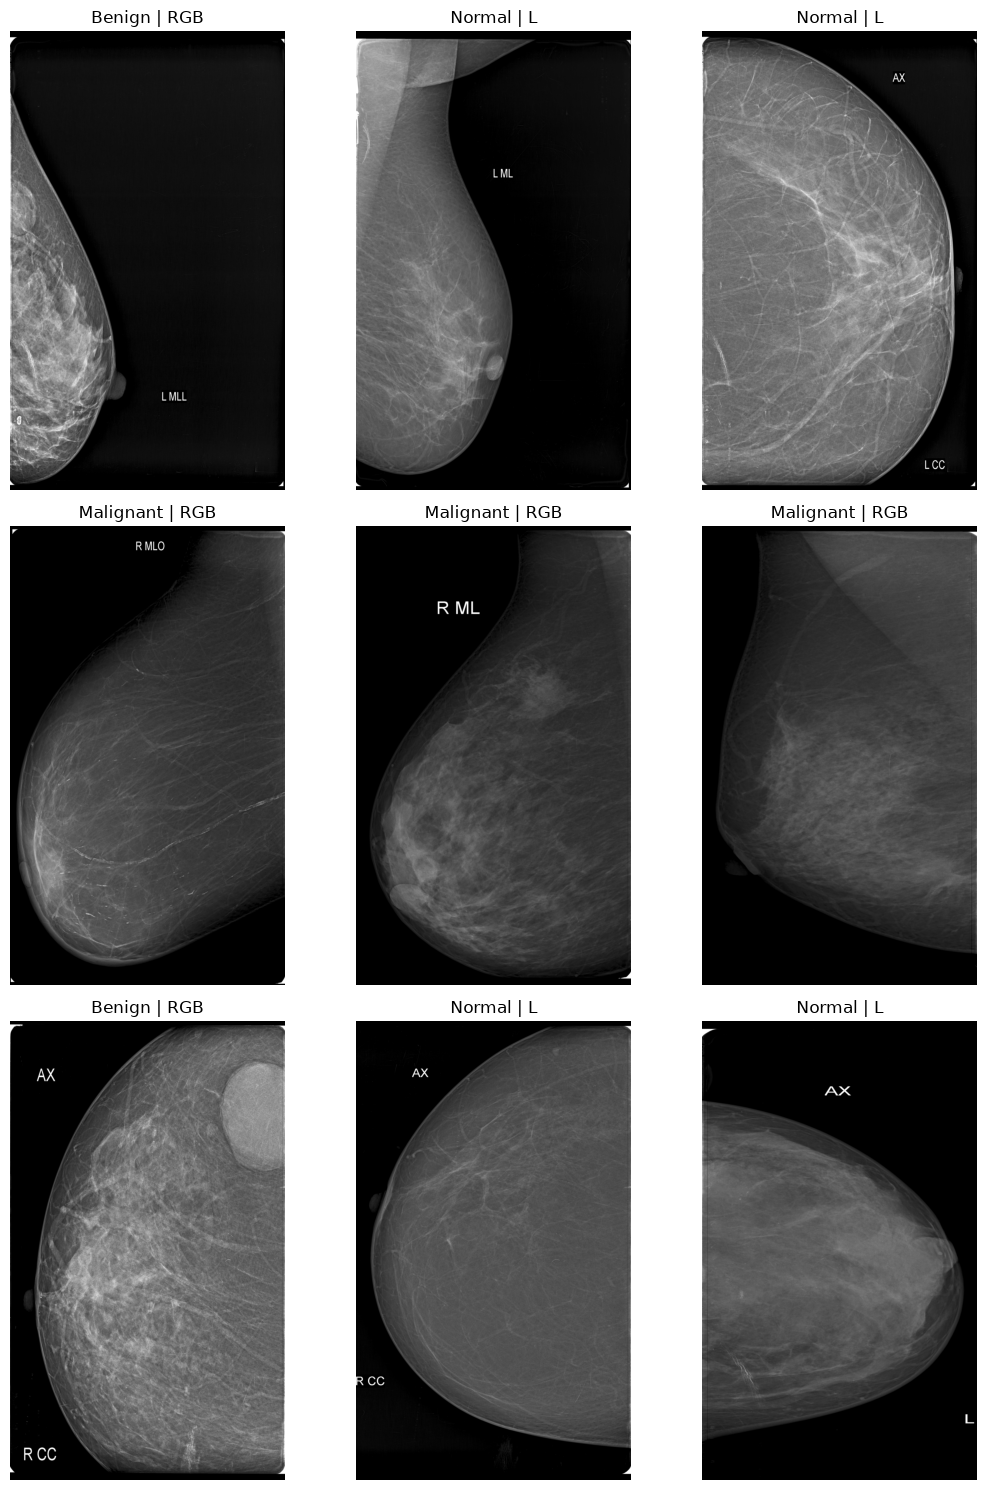

In [12]:
sample_rows = train_df.sample(min(9, len(train_df)), random_state=CFG.SEED)
fig, axes = plt.subplots(3, 3, figsize=(11, 15))
for ax, (_, row) in zip(axes.ravel(), sample_rows.iterrows()):
    image = cv2.imread(row['cache_path'], cv2.IMREAD_GRAYSCALE)
    ax.imshow(image, cmap='gray')
    ax.set_title(f"{row['label']} | {row['mode']}")
    ax.axis('off')
for ax in axes.ravel()[len(sample_rows):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

#### Insights

> Every visual sample now has the same grayscale content replicated across RGB channels, so the foundation encoder cannot infer the original storage mode from channel count.

> The original mode remains available only to the explicit calibration layer, making the shortcut measurable rather than hidden inside the network.

---

# Cross-Validation Design <a name="5"></a>

---

Five stratified folds are used because every fold still contains roughly ten Benign examples while each training partition retains 80% of the labelled data. Fold-specific mode priors are estimated from the training partition only.

## Fold Assignment

Out-of-fold rows never contribute to the model or mode prior used to predict themselves.

In [13]:
skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
train_df['fold'] = -1
for fold, (_, valid_idx) in enumerate(skf.split(train_df, train_df['target'])):
    train_df.loc[valid_idx, 'fold'] = fold

display(pd.crosstab(train_df['fold'], train_df['label']))

label,Benign,Malignant,Normal
fold,,,
0,11,16,16
1,11,16,16
2,10,16,16
3,10,16,16
4,10,16,16


#### Insights

> Five-fold ensembling increases the amount of labelled data seen by each model compared with the earlier three-fold run while preserving a full OOF prediction for calibration.

> Patient-disjoint validation cannot be reconstructed from the exposed competition CSV, so the OOF score should still be treated as a model-selection signal rather than an exact leaderboard estimate.

---

# Mammo-FM Multi-Task Model <a name="6"></a>

---

The official `BreastClipClassifier` reconstructs the Mammo-FM image encoder from the checkpoint config. A custom wrapper reuses the encoder features for both the direct three-class head and an auxiliary Benign-vs-Malignant head.

## Dataset and Augmentation

The official Mammo-FM downstream loader performs per-image min-max scaling followed by mammography-specific mean and standard deviation normalization. This notebook follows that normalization and uses moderate geometric augmentation.

In [14]:
TRAIN_AUG = Compose([
    HorizontalFlip(p=0.5),
    Affine(
        scale=(0.92, 1.08),
        translate_percent=(-0.04, 0.04),
        rotate=(-10, 10),
        shear=(-5, 5),
        border_mode=cv2.BORDER_CONSTANT,
        fill=0,
        p=0.75,
    ),
    RandomBrightnessContrast(brightness_limit=0.08, contrast_limit=0.08, p=0.30),
])

class MammogramDataset(Dataset):
    def __init__(self, df, augment=False, inference=False):
        self.df = df.reset_index(drop=True).copy()
        self.augment = augment
        self.inference = inference

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = cv2.imread(row['cache_path'], cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise ValueError(f"Could not read cached image: {row['cache_path']}")

        if self.augment:
            image = TRAIN_AUG(image=image)['image']

        image = image.astype(np.float32)
        image -= image.min()
        max_value = float(image.max())
        if max_value > 0:
            image /= max_value
        image = (image - CFG.MAMMO_MEAN) / CFG.MAMMO_STD
        tensor = torch.from_numpy(np.ascontiguousarray(image)).float().unsqueeze(0).repeat(3, 1, 1)

        if self.inference:
            return tensor, int(row['row_id'])

        return tensor, int(row['target']), int(row['bm_target']), int(row['row_id'])

## Model Definition

Batch-normalisation layers remain frozen during fine-tuning. Even with a 32 GB GPU, a physical batch of four high-resolution mammograms is still small for reliable BatchNorm statistics, so pretrained running statistics are preserved while convolutional weights adapt.

In [15]:
class HologyMammoFM(nn.Module):
    def __init__(self, vision_ckpt):
        super().__init__()
        args = SimpleNamespace(arch='breast_clip_det_b5_period_n_ft')
        self.foundation = BreastClipClassifier(args, ckpt=vision_ckpt, n_class=3)
        feature_dim = self.foundation.image_encoder.out_dim
        self.bm_head = nn.Sequential(
            nn.Dropout(0.30),
            nn.Linear(feature_dim, 2),
        )

    def encode(self, x):
        encoder = self.foundation.image_encoder
        if self.foundation.image_encoder_type == 'cnn':
            output = encoder({'image': x, 'breast_clip_train_mode': True})
            if isinstance(output, tuple):
                return output[0]
            return output
        output = encoder(x)
        return output[:, 0]

    def forward(self, x):
        features = self.encode(x)
        logits3 = self.foundation.classifier(features)
        logits_bm = self.bm_head(features)
        return logits3, logits_bm

def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model

def set_encoder_trainable(model, trainable):
    base = unwrap_model(model)
    for parameter in base.foundation.image_encoder.parameters():
        parameter.requires_grad = trainable

def freeze_batchnorm(model):
    base = unwrap_model(model)
    for module in base.foundation.image_encoder.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()
            for parameter in module.parameters():
                parameter.requires_grad = False

#### Insights

> The model now uses Mammo-FM's own image encoder and weight layout instead of loading the checkpoint into a separately recreated EfficientNet.

> The auxiliary pathology head does not replace the direct classifier. It adds targeted supervision for the Benign-versus-Malignant decision while the three-class head continues to learn the complete competition objective.

---

# Training and OOF Inference <a name="7"></a>

---

Each fold first trains only the new heads, then fine-tunes the full image encoder with a much smaller learning rate. The best epoch is selected by fused three-class Macro F1 on the held-out fold.

## Probability Fusion

The visual three-class probability is combined with the auxiliary pathology head and a fold-specific storage-mode prior. Mode evidence is expressed relative to the fold's global Normal prevalence so it adjusts the visual odds instead of replacing them.

In [16]:
def safe_logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=np.float64), eps, 1.0 - eps)
    return np.log(p / (1.0 - p))

def sigmoid_np(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -40, 40)))

def estimate_mode_prior(df):
    alpha = CFG.MODE_ALPHA
    global_normal = ((df['target'] == 0).sum() + alpha) / (len(df) + 2 * alpha)
    prior = {}
    for mode in df['mode'].unique():
        part = df[df['mode'] == mode]
        prior[mode] = ((part['target'] == 0).sum() + alpha) / (len(part) + 2 * alpha)
    return prior, float(global_normal)

def fuse_probabilities(p3, pbm, p_mode, p_global, beta=0.75, bm_weight=0.50):
    p3 = np.asarray(p3, dtype=np.float64)
    pbm = np.asarray(pbm, dtype=np.float64)
    p_mode = np.asarray(p_mode, dtype=np.float64)
    p_global = np.asarray(p_global, dtype=np.float64)

    normal_visual = np.clip(p3[:, 0], 1e-6, 1.0 - 1e-6)
    normal_adjusted = sigmoid_np(
        safe_logit(normal_visual) + beta * (safe_logit(p_mode) - safe_logit(p_global))
    )

    direct_cond = p3[:, 1:3] / np.clip(p3[:, 1:3].sum(axis=1, keepdims=True), 1e-8, None)
    pathology_cond = (1.0 - bm_weight) * direct_cond + bm_weight * pbm
    pathology_cond /= np.clip(pathology_cond.sum(axis=1, keepdims=True), 1e-8, None)

    fused = np.zeros((len(p3), 3), dtype=np.float64)
    fused[:, 0] = normal_adjusted
    fused[:, 1:3] = (1.0 - normal_adjusted[:, None]) * pathology_cond
    fused /= np.clip(fused.sum(axis=1, keepdims=True), 1e-8, None)
    return fused

## Training Utilities

Class weights are computed inside each training fold. The workstation profile uses mixed precision, channels-last tensors, pinned-memory loading, and a conservative default physical batch of two at 1520 x 912 on a 32 GB GPU. Gradient accumulation keeps the effective batch at approximately eight images; `HOLOGY_BATCH_SIZE` can be raised manually after a successful memory check.

In [17]:
def make_loader(df, train):
    dataset = MammogramDataset(df, augment=train, inference=False)
    return DataLoader(
        dataset,
        batch_size=CFG.BATCH_SIZE,
        shuffle=train,
        num_workers=CFG.NUM_WORKERS,
        pin_memory=True,
        drop_last=False,
        persistent_workers=CFG.NUM_WORKERS > 0,
        prefetch_factor=4 if CFG.NUM_WORKERS > 0 else None,
    )

def make_test_loader(df):
    dataset = MammogramDataset(df, augment=False, inference=True)
    return DataLoader(
        dataset,
        batch_size=CFG.BATCH_SIZE,
        shuffle=False,
        num_workers=CFG.NUM_WORKERS,
        pin_memory=True,
        drop_last=False,
        persistent_workers=CFG.NUM_WORKERS > 0,
        prefetch_factor=4 if CFG.NUM_WORKERS > 0 else None,
    )

def class_weights(values, n_classes):
    counts = np.bincount(np.asarray(values, dtype=int), minlength=n_classes)
    weights = len(values) / (n_classes * np.maximum(counts, 1))
    return torch.tensor(weights, dtype=torch.float32, device=CFG.DEVICE)

def predict_loader(model, loader, tta=False):
    model.eval()
    p3_all = []
    pbm_all = []
    row_ids = []

    with torch.no_grad():
        for batch in loader:
            images = batch[0].to(CFG.DEVICE, non_blocking=True)
            if CFG.CHANNELS_LAST:
                images = images.contiguous(memory_format=torch.channels_last)
            ids = batch[-1]
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=CFG.USE_AMP and torch.cuda.is_available()):
                logits3, logits_bm = model(images)
                probs3 = torch.softmax(logits3, dim=1)
                probs_bm = torch.softmax(logits_bm, dim=1)
                if tta:
                    flip3, flip_bm = model(torch.flip(images, dims=[3]))
                    probs3 = 0.5 * (probs3 + torch.softmax(flip3, dim=1))
                    probs_bm = 0.5 * (probs_bm + torch.softmax(flip_bm, dim=1))

            p3_all.append(probs3.float().cpu().numpy())
            pbm_all.append(probs_bm.float().cpu().numpy())
            row_ids.extend(ids.cpu().numpy().tolist())

    return np.concatenate(p3_all), np.concatenate(pbm_all), np.asarray(row_ids, dtype=int)

def train_epoch(model, loader, criterion3, criterion_bm, optimizer, scaler):
    model.train()
    freeze_batchnorm(model)
    optimizer.zero_grad(set_to_none=True)
    running = 0.0

    for step, (images, targets, bm_targets, _) in enumerate(loader):
        images = images.to(CFG.DEVICE, non_blocking=True)
        if CFG.CHANNELS_LAST:
            images = images.contiguous(memory_format=torch.channels_last)
        targets = targets.to(CFG.DEVICE, non_blocking=True)
        bm_targets = bm_targets.to(CFG.DEVICE, non_blocking=True)

        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=CFG.USE_AMP and torch.cuda.is_available()):
            logits3, logits_bm = model(images)
            loss3 = criterion3(logits3, targets)
            abnormal_mask = bm_targets >= 0
            if abnormal_mask.any():
                loss_bm = criterion_bm(logits_bm[abnormal_mask], bm_targets[abnormal_mask])
            else:
                loss_bm = logits_bm.sum() * 0.0
            loss = loss3 + CFG.BM_LOSS_WEIGHT * loss_bm
            scaled_loss = loss / CFG.ACCUM_STEPS

        scaler.scale(scaled_loss).backward()
        if (step + 1) % CFG.ACCUM_STEPS == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        running += float(loss.item()) * images.size(0)

    return running / len(loader.dataset)

## Five-Fold Training

The full foundation checkpoint is not reloaded for each fold. Every fold starts from the same filtered vision weights already held in CPU memory.

In [18]:
oof_p3 = np.zeros((len(train_df), 3), dtype=np.float32)
oof_pbm = np.zeros((len(train_df), 2), dtype=np.float32)
oof_mode_prior = np.zeros(len(train_df), dtype=np.float32)
oof_global_prior = np.zeros(len(train_df), dtype=np.float32)
test_fold_payloads = []
fold_scores = []

test_loader = make_test_loader(test_df)

for fold in range(CFG.N_FOLDS):
    print('\n' + '=' * 18 + f' FOLD {fold} ' + '=' * 18)
    seed_everything(CFG.SEED + fold)
    train_part = train_df[train_df['fold'] != fold].reset_index(drop=True)
    valid_part = train_df[train_df['fold'] == fold].reset_index(drop=True)
    train_loader = make_loader(train_part, train=True)
    valid_loader = make_loader(valid_part, train=False)

    mode_prior, global_prior = estimate_mode_prior(train_part)
    valid_mode_arr = np.array([mode_prior.get(m, global_prior) for m in valid_part['mode']], dtype=np.float32)
    test_mode_arr = np.array([mode_prior.get(m, global_prior) for m in test_df['mode']], dtype=np.float32)
    print('Mode prior:', mode_prior, '| global Normal:', round(global_prior, 4))

    model = HologyMammoFM(VISION_CKPT).to(CFG.DEVICE)
    if CFG.CHANNELS_LAST:
        model = model.to(memory_format=torch.channels_last)
    if CFG.N_GPU >= 2:
        model = nn.DataParallel(model)

    w3 = class_weights(train_part['target'].values, 3)
    abnormal_values = train_part.loc[train_part['bm_target'] >= 0, 'bm_target'].values
    wbm = class_weights(abnormal_values, 2)
    criterion3 = nn.CrossEntropyLoss(weight=w3, label_smoothing=CFG.LABEL_SMOOTHING)
    criterion_bm = nn.CrossEntropyLoss(weight=wbm, label_smoothing=CFG.LABEL_SMOOTHING)
    scaler = torch.cuda.amp.GradScaler(enabled=CFG.USE_AMP and torch.cuda.is_available())

    best_score = -1.0
    best_path = CFG.CHECKPOINT_DIR / f'fold_{fold}.pt'

    set_encoder_trainable(model, False)
    head_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = AdamW(head_params, lr=CFG.LR_HEAD, weight_decay=CFG.WEIGHT_DECAY)

    for epoch in range(CFG.HEAD_EPOCHS):
        loss = train_epoch(model, train_loader, criterion3, criterion_bm, optimizer, scaler)
        vp3, vpbm, row_ids = predict_loader(model, valid_loader, tta=False)
        fused = fuse_probabilities(
            vp3, vpbm, valid_mode_arr, np.full(len(valid_part), global_prior), beta=0.75, bm_weight=0.50
        )
        score = f1_score(valid_part['target'].values, fused.argmax(1), average='macro')
        print(f'Fold {fold} | head epoch {epoch + 1} | loss={loss:.4f} | macro_f1={score:.4f}')
        if score > best_score:
            best_score = score
            torch.save(unwrap_model(model).state_dict(), best_path)

    set_encoder_trainable(model, True)
    freeze_batchnorm(model)
    base = unwrap_model(model)
    encoder_params = [p for p in base.foundation.image_encoder.parameters() if p.requires_grad]
    head_params = list(base.foundation.classifier.parameters()) + list(base.bm_head.parameters())
    optimizer = AdamW([
        {'params': encoder_params, 'lr': CFG.LR_ENCODER},
        {'params': head_params, 'lr': CFG.LR_HEAD},
    ], weight_decay=CFG.WEIGHT_DECAY)
    scheduler = CosineAnnealingLR(optimizer, T_max=max(1, CFG.FINETUNE_EPOCHS), eta_min=1e-7)
    stale = 0

    for epoch in range(CFG.FINETUNE_EPOCHS):
        loss = train_epoch(model, train_loader, criterion3, criterion_bm, optimizer, scaler)
        vp3, vpbm, row_ids = predict_loader(model, valid_loader, tta=False)
        fused = fuse_probabilities(
            vp3, vpbm, valid_mode_arr, np.full(len(valid_part), global_prior), beta=0.75, bm_weight=0.50
        )
        score = f1_score(valid_part['target'].values, fused.argmax(1), average='macro')
        print(f'Fold {fold} | ft epoch {epoch + 1} | loss={loss:.4f} | macro_f1={score:.4f}')
        scheduler.step()

        if score > best_score + 1e-5:
            best_score = score
            stale = 0
            torch.save(unwrap_model(model).state_dict(), best_path)
        else:
            stale += 1
        if stale >= CFG.PATIENCE:
            print('Early stopping')
            break

    unwrap_model(model).load_state_dict(torch.load(best_path, map_location=CFG.DEVICE, weights_only=True))
    vp3, vpbm, val_ids = predict_loader(model, valid_loader, tta=True)
    tp3, tpbm, test_ids = predict_loader(model, test_loader, tta=True)

    oof_p3[val_ids] = vp3
    oof_pbm[val_ids] = vpbm
    oof_mode_prior[val_ids] = valid_mode_arr
    oof_global_prior[val_ids] = global_prior
    test_fold_payloads.append({
        'p3': tp3,
        'pbm': tpbm,
        'mode_prior': test_mode_arr,
        'global_prior': np.full(len(test_df), global_prior, dtype=np.float32),
    })

    fold_fused = fuse_probabilities(
        vp3, vpbm, valid_mode_arr, np.full(len(valid_part), global_prior), beta=0.75, bm_weight=0.50
    )
    fold_score = f1_score(valid_part['target'].values, fold_fused.argmax(1), average='macro')
    fold_scores.append(fold_score)
    print(f'Best fold {fold}: macro_f1={fold_score:.4f}')

    del model, optimizer, scheduler, scaler, train_loader, valid_loader
    gc.collect()
    torch.cuda.empty_cache()

print('Fold scores:', [round(x, 4) for x in fold_scores])
print('Mean fold Macro F1:', round(float(np.mean(fold_scores)), 4))


================== FOLD 0 ==================
Mode prior: {'L': np.float64(0.984375), 'RGB': np.float64(0.027522935779816515)} | global Normal: 0.3801
{'source': 'cnn', 'name': 'tf_efficientnet_b5_ns-detect', 'pretrained': True, 'model_type': 'cnn'}
Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b5-b6417697.pth" to /root/.cache/torch/hub/checkpoints/efficientnet-b5-b6417697.pth


100%|██████████| 117M/117M [01:54<00:00, 1.07MB/s] 


<All keys matched successfully>
Loaded pretrained weights for efficientnet-b5
Fold 0 | head epoch 1 | loss=1.5297 | macro_f1=0.7662
Fold 0 | head epoch 2 | loss=1.5125 | macro_f1=0.5814
Fold 0 | ft epoch 1 | loss=1.4410 | macro_f1=0.5814
Fold 0 | ft epoch 2 | loss=1.3477 | macro_f1=0.6786
Fold 0 | ft epoch 3 | loss=1.2521 | macro_f1=0.6786
Early stopping
Best fold 0: macro_f1=0.7662

================== FOLD 1 ==================
Mode prior: {'L': np.float64(0.984375), 'RGB': np.float64(0.027522935779816515)} | global Normal: 0.3801
{'source': 'cnn', 'name': 'tf_efficientnet_b5_ns-detect', 'pretrained': True, 'model_type': 'cnn'}
<All keys matched successfully>
Loaded pretrained weights for efficientnet-b5
Fold 1 | head epoch 1 | loss=1.5374 | macro_f1=0.8233
Fold 1 | head epoch 2 | loss=1.4791 | macro_f1=0.5714
Fold 1 | ft epoch 1 | loss=1.4549 | macro_f1=0.7632
Fold 1 | ft epoch 2 | loss=1.3725 | macro_f1=0.6786
Fold 1 | ft epoch 3 | loss=1.2709 | macro_f1=0.6786
Early stopping
Best fo

#### Insights

> Fold checkpoints are selected using the actual three-class competition metric rather than training loss.

> Horizontal-flip TTA is used only after the best checkpoint is chosen, keeping epoch selection fast while stabilising the final OOF and test probabilities.

---

# OOF Calibration <a name="8"></a>

---

The model architecture is fixed at this point. Only the probability-combination parameters are calibrated against held-out OOF predictions, which costs no additional GPU training.

## Tune Mode and Pathology Fusion

A small grid searches how strongly the explicit storage-mode prior and auxiliary Benign-vs-Malignant head should influence the direct Mammo-FM probabilities.

In [19]:
y_true = train_df['target'].values
best = {'score': -1.0, 'beta': None, 'bm_weight': None, 'probs': None}
for beta in np.arange(0.0, 1.51, 0.25):
    for bm_weight in np.arange(0.0, 1.01, 0.25):
        probs = fuse_probabilities(
            oof_p3, oof_pbm, oof_mode_prior, oof_global_prior, beta=float(beta), bm_weight=float(bm_weight)
        )
        score = f1_score(y_true, probs.argmax(1), average='macro')
        if score > best['score']:
            best = {'score': float(score), 'beta': float(beta), 'bm_weight': float(bm_weight), 'probs': probs}

print('Best fusion:', {k: v for k, v in best.items() if k != 'probs'})

Best fusion: {'score': 0.7926587301587301, 'beta': 0.25, 'bm_weight': 0.75}


## Macro-F1 Class Bias

Macro F1 depends on hard decisions rather than probability calibration alone. A small additive log-probability bias for Benign and Malignant is therefore selected on OOF predictions.

In [20]:
def predict_with_bias(probs, benign_bias=0.0, malignant_bias=0.0):
    scores = np.log(np.clip(probs, 1e-8, 1.0))
    scores[:, 1] += benign_bias
    scores[:, 2] += malignant_bias
    return scores.argmax(1)

best_bias = {'score': best['score'], 'benign': 0.0, 'malignant': 0.0}
bias_values = np.arange(-0.30, 0.31, 0.05)
for benign_bias, malignant_bias in product(bias_values, bias_values):
    pred = predict_with_bias(best['probs'], float(benign_bias), float(malignant_bias))
    score = f1_score(y_true, pred, average='macro')
    if score > best_bias['score']:
        best_bias = {
            'score': float(score),
            'benign': float(benign_bias),
            'malignant': float(malignant_bias),
        }

oof_pred = predict_with_bias(best['probs'], best_bias['benign'], best_bias['malignant'])
print('Best bias:', best_bias)
print(classification_report(y_true, oof_pred, target_names=CFG.LABELS, digits=4))
print('Confusion matrix:')
print(confusion_matrix(y_true, oof_pred))

Best bias: {'score': 0.7926587301587301, 'benign': 0.0, 'malignant': 0.0}
              precision    recall  f1-score   support

      Normal     1.0000    1.0000    1.0000        80
      Benign     0.6591    0.5577    0.6042        52
   Malignant     0.7386    0.8125    0.7738        80

    accuracy                         0.8208       212
   macro avg     0.7992    0.7901    0.7927       212
weighted avg     0.8178    0.8208    0.8176       212

Confusion matrix:
[[80  0  0]
 [ 0 29 23]
 [ 0 15 65]]


## Save OOF Diagnostics

The OOF file keeps all raw and fused probabilities so the next experiment can be compared without retraining this model.

In [21]:
oof_df = train_df[['image_id', 'label', 'target', 'mode', 'fold']].copy()
for i, name in enumerate(CFG.LABELS):
    oof_df[f'p3_{name.lower()}'] = oof_p3[:, i]
    oof_df[f'fused_{name.lower()}'] = best['probs'][:, i]
oof_df['pbm_benign'] = oof_pbm[:, 0]
oof_df['pbm_malignant'] = oof_pbm[:, 1]
oof_df['prediction'] = [CFG.IDX2LABEL[int(x)] for x in oof_pred]
oof_df.to_csv(CFG.RESULT_DIR / 'oof_predictions.csv', index=False)
display(oof_df.head())

,image_id,label,target,mode,fold,p3_normal,fused_normal,p3_benign,fused_benign,p3_malignant,fused_malignant,pbm_benign,pbm_malignant,prediction
0,image_0001.jpg,Normal,0,L,1,0.378314,0.659561,0.309366,0.167822,0.312320,0.172617,0.491401,0.508599,Normal
1,image_0003.jpg,Normal,0,L,0,0.352256,0.633882,0.349778,0.192064,0.297966,0.174054,0.519463,0.480537,Normal
2,image_0004.jpg,Benign,1,RGB,2,0.419903,0.232637,0.296878,0.376821,0.283219,0.390542,0.484155,0.515845,Malignant
3,image_0005.jpg,Normal,0,L,1,0.379922,0.661093,0.305138,0.154403,0.314940,0.184504,0.443422,0.556577,Normal
4,image_0006.jpg,Benign,1,RGB,0,0.348570,0.198726,0.345454,0.362354,0.305975,0.438920,0.426196,0.573804,Malignant


#### Insights

> The key score to trust is the final OOF Macro F1 after fusion and bias calibration, together with the per-class F1 values.

> If the optimum mode beta collapses to zero, Mammo-FM is already extracting enough information visually and the shortcut should be excluded from the submission.

---

# Test Ensemble <a name="9"></a>

---

Each fold's test probabilities are fused with that fold's own training-derived mode prior using the OOF-selected parameters. The fold-level fused distributions are then averaged.

## Fold Ensemble

No public leaderboard information is used to choose the ensemble parameters.

In [22]:
test_fused_folds = []
for payload in test_fold_payloads:
    fold_probs = fuse_probabilities(
        payload['p3'],
        payload['pbm'],
        payload['mode_prior'],
        payload['global_prior'],
        beta=best['beta'],
        bm_weight=best['bm_weight'],
    )
    test_fused_folds.append(fold_probs)

test_probs = np.mean(test_fused_folds, axis=0)
test_pred_raw = test_probs.argmax(1)
test_pred_cal = predict_with_bias(test_probs, best_bias['benign'], best_bias['malignant'])

test_diag = test_df[['image_id', 'mode']].copy()
for i, name in enumerate(CFG.LABELS):
    test_diag[f'p_{name.lower()}'] = test_probs[:, i]
test_diag['raw_prediction'] = [CFG.IDX2LABEL[int(x)] for x in test_pred_raw]
test_diag['calibrated_prediction'] = [CFG.IDX2LABEL[int(x)] for x in test_pred_cal]
test_diag['confidence'] = test_probs.max(axis=1)
test_diag.to_csv(CFG.RESULT_DIR / 'test_probabilities.csv', index=False)
display(test_diag.sort_values('confidence').head(15))

,image_id,mode,p_normal,p_benign,p_malignant,raw_prediction,calibrated_prediction,confidence
29,image_0147.jpg,RGB,0.297458,0.357881,0.344661,Benign,Benign,0.357881
52,image_0255.jpg,RGB,0.314137,0.325250,0.360613,Malignant,Malignant,0.360613
16,image_0062.jpg,RGB,0.262473,0.356896,0.380631,Malignant,Malignant,0.380631
17,image_0072.jpg,RGB,0.229039,0.395608,0.375353,Benign,Benign,0.395608
35,image_0170.jpg,RGB,0.240524,0.359708,0.399767,Malignant,Malignant,0.399767
24,image_0103.jpg,RGB,0.196705,0.394218,0.409076,Malignant,Malignant,0.409076
32,image_0155.jpg,RGB,0.179918,0.413617,0.406466,Benign,Benign,0.413617
27,image_0127.jpg,RGB,0.202164,0.381368,0.416469,Malignant,Malignant,0.416469
41,image_0198.jpg,RGB,0.251274,0.328307,0.420418,Malignant,Malignant,0.420418
31,image_0150.jpg,RGB,0.172382,0.425920,0.401697,Benign,Benign,0.425920


#### Insights

> Low-confidence images are the most useful rows to inspect before spending a Kaggle submission slot.

> Both raw and Macro-F1-calibrated predictions are retained so the local calibration gain is transparent.

---

# Submission <a name="10"></a>

---

Two valid CSV files are generated. The calibrated file is the default recommendation only when its OOF Macro F1 exceeds the un-biased fused prediction.

## Generate Submission Files

Both files preserve the exact `image_id` order from `test.csv`.

In [23]:
raw_submission = test_df[['image_id']].copy()
raw_submission['label'] = [CFG.IDX2LABEL[int(x)] for x in test_pred_raw]
raw_path = CFG.RESULT_DIR / 'submission_mammofm_fused.csv'
raw_submission.to_csv(raw_path, index=False)

cal_submission = test_df[['image_id']].copy()
cal_submission['label'] = [CFG.IDX2LABEL[int(x)] for x in test_pred_cal]
cal_path = CFG.RESULT_DIR / 'submission_mammofm_calibrated.csv'
cal_submission.to_csv(cal_path, index=False)

assert list(raw_submission.columns) == ['image_id', 'label']
assert list(cal_submission.columns) == ['image_id', 'label']
assert len(raw_submission) == len(test_df) == len(sample_submission)
assert set(raw_submission['label']).issubset(set(CFG.LABELS))
assert set(cal_submission['label']).issubset(set(CFG.LABELS))

print('Raw submission:', raw_path)
print(raw_submission['label'].value_counts())
print('\nCalibrated submission:', cal_path)
print(cal_submission['label'].value_counts())
print('\nOOF fused score:', round(best['score'], 5))
print('OOF calibrated score:', round(best_bias['score'], 5))
display(cal_submission.head())

Raw submission: /workspace/hology_mammofm_workstation_v2/results/submission_mammofm_fused.csv
label
Normal       20
Malignant    20
Benign       14
Name: count, dtype: int64

Calibrated submission: /workspace/hology_mammofm_workstation_v2/results/submission_mammofm_calibrated.csv
label
Normal       20
Malignant    20
Benign       14
Name: count, dtype: int64

OOF fused score: 0.79266
OOF calibrated score: 0.79266


,image_id,label
0,image_0002.jpg,Normal
1,image_0014.jpg,Malignant
2,image_0016.jpg,Normal
3,image_0021.jpg,Benign
4,image_0023.jpg,Malignant


#### Insights

> Submit `submission_mammofm_calibrated.csv` first when the calibrated OOF score is higher. If the bias search produces no gain, use `submission_mammofm_fused.csv` instead.

---

# Experiment Summary <a name="11"></a>

---

This final cell records the experiment configuration and the quantities that should drive the next submission decision.

In [24]:
summary = pd.DataFrame([{
    'model': 'Mammo-FM BatmanLab EfficientNet-B5',
    'resolution': f'{CFG.IMG_H}x{CFG.IMG_W}',
    'folds': CFG.N_FOLDS,
    'mean_fold_macro_f1': float(np.mean(fold_scores)),
    'oof_fusion_macro_f1': best['score'],
    'oof_calibrated_macro_f1': best_bias['score'],
    'mode_beta': best['beta'],
    'bm_weight': best['bm_weight'],
    'benign_bias': best_bias['benign'],
    'malignant_bias': best_bias['malignant'],
}])
display(summary.T)
summary.to_csv(CFG.RESULT_DIR / 'experiment_summary.csv', index=False)

,0
model,Mammo-FM BatmanLab EfficientNet-B5
resolution,1520x912
folds,5
mean_fold_macro_f1,0.764128
oof_fusion_macro_f1,0.792659
oof_calibrated_macro_f1,0.792659
mode_beta,0.25
bm_weight,0.75
benign_bias,0.0
malignant_bias,0.0


#### Insights

> This run should be judged primarily by OOF Macro F1 and the Benign and Malignant class F1 values. The public leaderboard contains too few images to be a reliable tuning target.

> Mammo-FM weights are licensed for non-commercial academic research and benchmarking. This notebook uses the model for competition research only and does not constitute clinical use.

> The current machine has ephemeral local storage, so copy the `results/` directory and any desired checkpoints off the instance before terminating it.